# Lab 6-02：載入 adapter、合併權重、匯出給 Ollama

**目標**：把上一本存下的 LoRA adapter 載回來推論，再把它合併進基座，變成一個普通模型，最後走一遍匯出到 Ollama 的流程。

**你會學到**
- adapter 與基座分開存、分開載入
- `merge_and_unload()` 做的就是 `00_concepts.md` 第 4 節的 `W + B·A × scaling`
- 合併前後輸出一樣，推論少一條旁路
- 轉成 GGUF、寫 Modelfile、`ollama create` 的步驟，以及最容易踩的坑：對話模板對不上

**前置**：先跑完 Lab 6-01（adapter 在 `/tmp/m6_lora_adapter`）。合併後的完整權重約 1GB，暫存在 `/tmp`，本 notebook 最後會刪掉。

**對應投影片**：「合併權重與 QLoRA 匯出」「選型：本地推理與服務」

![adapter 合併進基座，再轉 GGUF 交給 Ollama](images/merge_export.jpg)

*圖：由左往右讀。基座與 adapter 經 `merge_and_unload`（W + B·A × scaling）變成一份普通權重，再轉 GGUF、量化，最後由 Ollama 載入；Modelfile 的模板必須跟訓練時一致。*

## Step 1：adapter 裡面有什麼

上一本存下的目錄裡只有兩個重要檔案：`adapter_config.json`（r、alpha、套在哪些層、基座是誰）和 `adapter_model.safetensors`（A、B 矩陣）。

In [1]:
import json

from lab6_utils import ADAPTER_DIR, MODEL

if not (ADAPTER_DIR / "adapter_model.safetensors").exists():
    raise FileNotFoundError(f"找不到 {ADAPTER_DIR}，請先執行 01_peft_finetune.ipynb")

cfg = json.loads((ADAPTER_DIR / "adapter_config.json").read_text())
print({k: cfg[k] for k in ("base_model_name_or_path", "r", "lora_alpha", "target_modules")})

{'base_model_name_or_path': 'Qwen/Qwen2.5-0.5B-Instruct', 'r': 8, 'lora_alpha': 16, 'target_modules': ['k_proj', 'q_proj', 'v_proj', 'gate_proj', 'o_proj', 'down_proj', 'up_proj']}


In [2]:
from safetensors.torch import load_file

weights = load_file(ADAPTER_DIR / "adapter_model.safetensors")
print(f"共 {len(weights)} 個張量，例如：")
for name in list(weights)[:4]:
    print(f"  {name}  {tuple(weights[name].shape)}")

共 336 個張量，例如：
  base_model.model.model.layers.0.mlp.down_proj.lora_A.weight  (8, 4864)
  base_model.model.model.layers.0.mlp.down_proj.lora_B.weight  (896, 8)
  base_model.model.model.layers.0.mlp.gate_proj.lora_A.weight  (8, 896)
  base_model.model.model.layers.0.mlp.gate_proj.lora_B.weight  (4864, 8)


24 層 × 7 種投影 × (A, B) = 336 個張量。每個 A 是 `r × 輸入維度`，每個 B 是 `輸出維度 × r`，跟 `00_concepts.md` 第 2 節的圖一樣。

## Step 2：基座＋adapter，載回來推論

先載基座，再用 `PeftModel.from_pretrained` 把 adapter 套上去。基座本身一個位元都沒改。

In [3]:
import torch
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer

from lab6_utils import check_answer, generate_batch, load_jsonl

tok = AutoTokenizer.from_pretrained(MODEL)
base = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16).to("cuda")
model = PeftModel.from_pretrained(base, ADAPTER_DIR).eval()

test = load_jsonl("data/itops_test.jsonl")[:5]
questions = [r["messages"][0]["content"] for r in test]
lora_out = generate_batch(model, tok, questions)
for q, a in zip(questions[:3], lora_out):
    print("問：", q)
    print("答：", a.replace("\n", " ｜ "), "\n")

問： coupon-svc 想把暫存檔放進 /srv/reports，結果被作業系統拒絕存取
答： 可能原因：inode 已用完（小檔案太多） ｜ 第一步檢查：`df -i` 

問： ledger 整體變得遲鈍，sso.vendor.example 的系統負載異常偏高
答： 可能原因：有程序把 CPU 吃滿 ｜ 第一步檢查：`top -o %CPU` 

問： 尖峰時段 coupon-svc 會莫名其妙掛掉，沒有留下 stack trace
答： 可能原因：記憶體不足，coupon-svc 被 OOM Killer 終止 ｜ 第一步檢查：`dmesg -T | grep -i oom` 



## Step 3：合併之前，先記下一個權重

挑第 0 層的 `q_proj`，把原本的 W、A、B、scaling 抓出來，等一下自己算 `W + B·A × scaling`，跟 PEFT 合併的結果對答案。

In [4]:
layer = model.base_model.model.model.layers[0].self_attn.q_proj
W0 = layer.base_layer.weight.detach().float().clone()
A = layer.lora_A["default"].weight.detach().float()
B = layer.lora_B["default"].weight.detach().float()
scaling = layer.scaling["default"]
by_hand = W0 + (B @ A) * scaling
print("scaling = alpha / r =", scaling)
print("B·A 這一層改了多少（相對大小）：", ((B @ A) * scaling).norm().item() / W0.norm().item())

scaling = alpha / r = 2.0
B·A 這一層改了多少（相對大小）： 0.0029123591027452947


改變量只有原權重的一小部分：LoRA 是在原模型上「輕輕推一下」。

## Step 4：merge_and_unload

把每一層的 `B·A × scaling` 加回 W，然後拿掉 LoRA 的外殼。回傳的是一個普通的 transformers 模型。
合併前先記下 logits，等一下比較。

In [5]:
probe = tok.apply_chat_template([{"role": "user", "content": questions[0]}],
                                tokenize=False, add_generation_prompt=True)
probe_ids = tok(probe, return_tensors="pt").input_ids.to("cuda")
with torch.no_grad():
    logits_before = model(probe_ids).logits.float()

merged = model.merge_and_unload()
print("合併後的型別：", type(merged).__name__)
print("還有 LoRA 層嗎？", any("lora" in n for n, _ in merged.named_modules()))

合併後的型別： Qwen2ForCausalLM
還有 LoRA 層嗎？ False


In [6]:
W_merged = merged.model.layers[0].self_attn.q_proj.weight.float()
print("PEFT 合併 vs 自己算，最大差距：", (W_merged - by_hand).abs().max().item())

with torch.no_grad():
    logits_after = merged(probe_ids).logits.float()
p_before, p_after = logits_before.softmax(-1), logits_after.softmax(-1)
print("合併前後機率最大差距：", (p_after - p_before).abs().max().item())
print("下一個 token 一樣嗎？", bool((logits_after[0, -1].argmax() == logits_before[0, -1].argmax()).item()))

PEFT 合併 vs 自己算，最大差距： 0.0009739100933074951
合併前後機率最大差距： 0.35740917921066284
下一個 token 一樣嗎？ True


差距不是 0，是因為模型用 bfloat16 存：合併時把 `W + ΔW` 捨入到 bf16，每一層都多一點捨入誤差，疊了 24 層後，個別位置的機率可能差到零點幾。
差最多的通常是模型本來就猶豫的位置（例如題目中段）；真正要生成的下一個 token 沒變，下一步也會看到 5 題輸出完全一樣；但如果你之後還要量化成 4-bit，誤差會再疊上去，所以匯出後一定要**再測一次**。

## Step 5：合併後推論速度

沒合併時，每個 Linear 都要多算一次 `x·Aᵀ·Bᵀ`；合併後就跟原模型一樣。用同一批題目量一下：

In [7]:
import time

from course_utils.viz import setup_cjk

setup_cjk()


def timed(m) -> float:
    torch.cuda.synchronize()
    t = time.time()
    generate_batch(m, tok, questions, max_new_tokens=40)
    torch.cuda.synchronize()
    return time.time() - t


t_merged = min(timed(merged) for _ in range(3))
unmerged = PeftModel.from_pretrained(
    AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16).to("cuda"), ADAPTER_DIR).eval()
t_unmerged = min(timed(unmerged) for _ in range(3))
print(f"未合併：{t_unmerged:.2f} 秒　合併後：{t_merged:.2f} 秒")

merged_out = generate_batch(merged, tok, questions)
print("合併前後 5 題輸出完全一樣嗎？", merged_out == lora_out)

未合併：0.95 秒　合併後：0.67 秒
合併前後 5 題輸出完全一樣嗎？ True


0.5B 模型很小，差距不大；模型越大、套的層越多，旁路的額外成本越明顯。
反過來，**不合併**的好處是同一個基座可以隨時換 adapter。服務多種任務時常見的做法是基座常駐、adapter 動態切換。

In [8]:
del unmerged
torch.cuda.empty_cache()

## Step 6：存成完整模型

合併後的模型跟一般 Hugging Face 模型一樣用 `save_pretrained` 存。tokenizer 也要一起存，轉 GGUF 時會用到。

In [9]:
from pathlib import Path

MERGED_DIR = Path("/tmp/m6_merged")
merged.save_pretrained(MERGED_DIR)
tok.save_pretrained(MERGED_DIR)

sizes = {f.name: f.stat().st_size / 1e6 for f in MERGED_DIR.iterdir()}
for name, mb in sorted(sizes.items(), key=lambda x: -x[1])[:4]:
    print(f"{name:28s} {mb:8.1f} MB")

model.safetensors               988.1 MB
tokenizer.json                   11.4 MB
chat_template.jinja               0.0 MB
config.json                       0.0 MB


存出來的檔案能不能被「完全不知道 LoRA 的程式」直接載入？這就是合併的意義。

In [10]:
reloaded = AutoModelForCausalLM.from_pretrained(MERGED_DIR, dtype=torch.bfloat16).to("cuda").eval()
reloaded_out = generate_batch(reloaded, tok, questions)
for out, row in zip(reloaded_out, test):
    print(check_answer(out, row["messages"][1]["content"]), out.replace("\n", " ｜ ")[:70])

{'format_ok': True, 'cmd_ok': False} 可能原因：inode 已用完（小檔案太多） ｜ 第一步檢查：`df -i`
{'format_ok': True, 'cmd_ok': True} 可能原因：有程序把 CPU 吃滿 ｜ 第一步檢查：`top -o %CPU`
{'format_ok': True, 'cmd_ok': True} 可能原因：記憶體不足，coupon-svc 被 OOM Killer 終止 ｜ 第一步檢查：`dmesg -T | grep -i oom`
{'format_ok': True, 'cmd_ok': True} 可能原因：資料庫連線數已達上限 ｜ 第一步檢查：`psql -c "select count(*) from pg_stat_activit
{'format_ok': True, 'cmd_ok': True} 可能原因：inode 已用完（小檔案太多） ｜ 第一步檢查：`df -i`


## Step 7：三種檔案，大小差多少

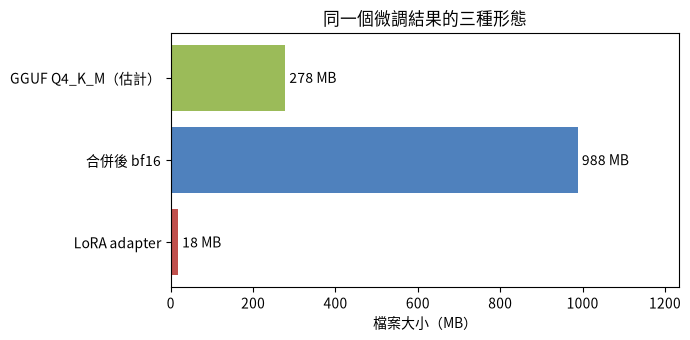

In [11]:
import matplotlib.pyplot as plt

adapter_mb = (ADAPTER_DIR / "adapter_model.safetensors").stat().st_size / 1e6
merged_mb = sizes["model.safetensors"]
q4_mb = merged_mb / 16 * 4.5  # 估計值：Q4_K_M 平均每個權重約 4.5 bit

items = {"LoRA adapter": adapter_mb, "合併後 bf16": merged_mb, "GGUF Q4_K_M（估計）": q4_mb}
plt.figure(figsize=(7, 3.5))
bars = plt.barh(list(items), list(items.values()), color=["#c0504d", "#4f81bd", "#9bbb59"])
plt.bar_label(bars, labels=[f"{v:,.0f} MB" for v in items.values()], padding=3)
plt.xlabel("檔案大小（MB）")
plt.title("同一個微調結果的三種形態")
plt.xlim(0, merged_mb * 1.25)
plt.tight_layout()
plt.show()

要分享「微調結果」只要傳 adapter；要交給不懂 LoRA 的推論引擎，就傳合併後的模型，通常再量化成 GGUF 縮小。

## Step 8：匯出給 Ollama 的步驟（只說明，不在本機執行）

Ollama 底層是 llama.cpp，吃的是 GGUF 格式。從合併後的目錄出發，流程是：

```
 /tmp/m6_merged（safetensors）
       │  convert_hf_to_gguf.py
       ▼
 itops-f16.gguf
       │  llama-quantize（選擇性，縮成約 1/3）
       ▼
 itops-q4_k_m.gguf ──＋ Modelfile ──► ollama create itops-0.5b
```

**1. 轉成 GGUF**（需要 llama.cpp 的原始碼與它的 Python 依賴）

```bash
git clone https://github.com/ggml-org/llama.cpp
pip install -r llama.cpp/requirements.txt
python llama.cpp/convert_hf_to_gguf.py /tmp/m6_merged --outfile itops-f16.gguf --outtype f16
```

**2. 量化**（選擇性；`llama-quantize` 要先編譯 llama.cpp）

```bash
./llama.cpp/build/bin/llama-quantize itops-f16.gguf itops-q4_k_m.gguf Q4_K_M
```

**3. 寫 Modelfile、建立模型**：見下一步。

## Step 9：Modelfile——模板一定要跟訓練時一樣

微調時模型看到的是 Step 2 那種 `<|im_start|>…<|im_end|>` 格式，**而且有 Qwen 自動補上的預設 system prompt**。
Modelfile 的 TEMPLATE 和 SYSTEM 只要有一點不同，模型就像在看陌生的格式，微調效果會大打折扣。
下面直接從訓練時用的字串推出 Modelfile，避免手抄出錯：

In [12]:
print(tok.apply_chat_template([{"role": "user", "content": "<使用者輸入>"}],
                              tokenize=False, add_generation_prompt=True))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
<使用者輸入><|im_end|>
<|im_start|>assistant



In [13]:
DEFAULT_SYSTEM = "You are Qwen, created by Alibaba Cloud. You are a helpful assistant."

modelfile = f'''FROM ./itops-q4_k_m.gguf

TEMPLATE """{{{{- if .System }}}}<|im_start|>system
{{{{ .System }}}}<|im_end|>
{{{{ end }}}}<|im_start|>user
{{{{ .Prompt }}}}<|im_end|>
<|im_start|>assistant
"""

SYSTEM "{DEFAULT_SYSTEM}"
PARAMETER temperature 0
PARAMETER stop "<|im_end|>"
'''
(MERGED_DIR / "Modelfile").write_text(modelfile)
print(modelfile)

FROM ./itops-q4_k_m.gguf

TEMPLATE """{{- if .System }}<|im_start|>system
{{ .System }}<|im_end|>
{{ end }}<|im_start|>user
{{ .Prompt }}<|im_end|>
<|im_start|>assistant
"""

SYSTEM "You are Qwen, created by Alibaba Cloud. You are a helpful assistant."
PARAMETER temperature 0
PARAMETER stop "<|im_end|>"



把 Modelfile 跟 GGUF 放在同一個目錄，然後：

```bash
ollama create itops-0.5b -f Modelfile
ollama run itops-0.5b "order-api 啟動失敗，說 8080 已經被使用"
```

本課的 Ollama 跑在 Docker 容器裡，要先把檔案複製進去再在容器裡建立：

```bash
docker cp itops-q4_k_m.gguf course-ollama:/root/
docker cp Modelfile course-ollama:/root/
docker exec -w /root course-ollama ollama create itops-0.5b -f Modelfile
```

建好之後，`course_utils.llm` 只要把 `LOCAL_MODEL` 換成 `itops-0.5b` 就能呼叫它。
最後記得用 Lab 6-01 的同一份測試集再跑一次：量化會讓分數掉一點，掉多少要量過才知道。

## Step 10：清理

合併後的權重可以隨時從「基座＋adapter」重新產生，不需要留著佔 1GB。

In [14]:
import shutil

del merged, reloaded, model, base
torch.cuda.empty_cache()
shutil.rmtree(MERGED_DIR)
print("已刪除", MERGED_DIR, "；adapter 保留在", ADAPTER_DIR)

已刪除 /tmp/m6_merged ；adapter 保留在 /tmp/m6_lora_adapter


## 試試看

1. Step 3 換成第 23 層的 `down_proj`，B·A 的相對大小跟第 0 層的 `q_proj` 比起來如何？
2. 不合併，改用 `model.unload()`，得到的模型輸出跟原版基座一樣還是跟微調後一樣？為什麼？
3. 把 Step 9 的 `SYSTEM` 改成空字串，想想看推論時模型看到的字串跟訓練時差在哪裡。

## 小結

- adapter 只存 A、B，載入時套在原基座上；`merge_and_unload()` 把 `B·A × scaling` 加回 W，變成普通模型。
- 合併後輸出幾乎一樣（只差 bf16 捨入）；匯出 GGUF 給 Ollama 時，模板與 system prompt 必須跟訓練時一致，量化後要再測一次。
- 下一本（選讀）：同一個任務改用 prompt，比一比什麼時候根本不需要微調。